# Page: size flags or anchors (`addons/_core_editor/plugin.gd`)

**Rule of thumb:** look at the *parent*. If the parent is a `Container`, size the child with **size flags**. If the parent is a plain `Control`, size the child with **anchors**. The wrong one does nothing and raises no error.

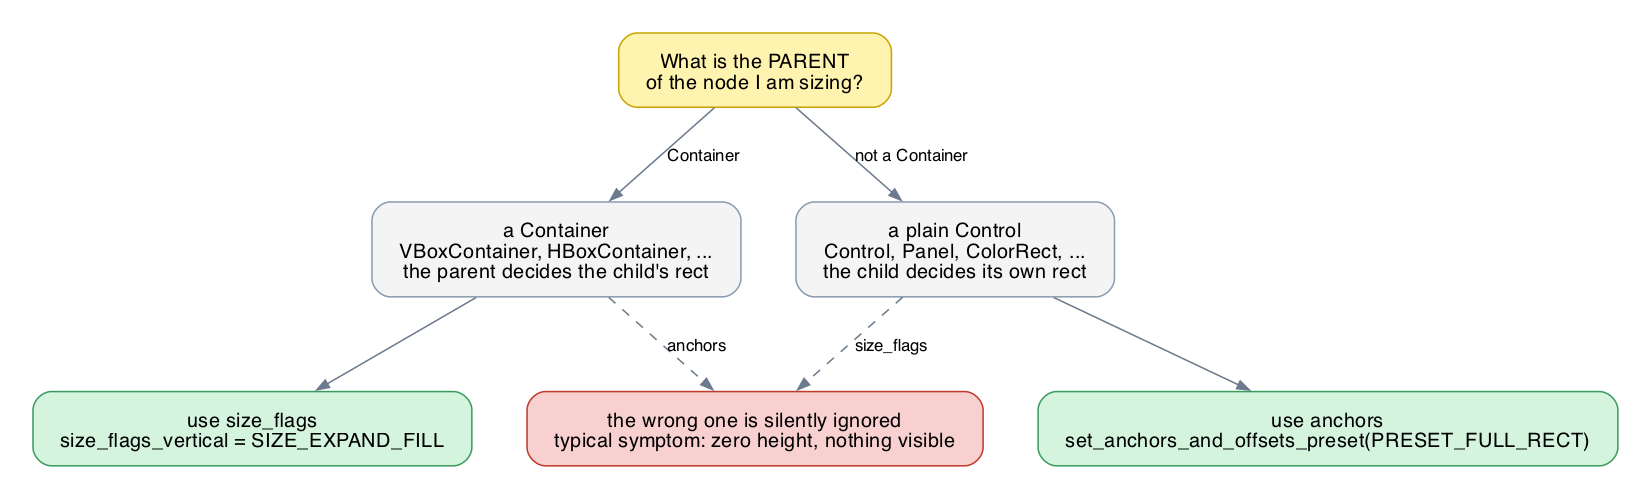

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  rankdir=TB;
  node [shape=box, style="rounded,filled", fillcolor="#f4f4f4", fontname="Helvetica"];
  edge [fontname="Helvetica", fontsize=11];
  ask    [label="What is the PARENT\nof the node I am sizing?", fillcolor="#fff3b0", color="#c9a400"];
  cont   [label="a Container\nVBoxContainer, HBoxContainer, ...\nthe parent decides the child's rect"];
  plain  [label="a plain Control\nControl, Panel, ColorRect, ...\nthe child decides its own rect"];
  flags  [label="use size_flags\nsize_flags_vertical = SIZE_EXPAND_FILL", fillcolor="#d4f4dd", color="#3c9a5f"];
  anch   [label="use anchors\nset_anchors_and_offsets_preset(PRESET_FULL_RECT)", fillcolor="#d4f4dd", color="#3c9a5f"];
  bad    [label="the wrong one is silently ignored\ntypical symptom: zero height, nothing visible", fillcolor="#f9d0d0", color="#c0392b"];
  ask -> cont  [label="Container"];
  ask -> plain [label="not a Container"];
  cont -> flags;
  plain -> anch;
  cont -> bad  [label="anchors", style=dashed];
  plain -> bad [label="size_flags", style=dashed];
}
```

</details>

The three levels in the Core main screen, top to bottom:

| Node | Its parent | Parent is a | So use | Line |
|---|---|---|---|---|
| `main_screen_root` | the editor's main screen | `VBoxContainer` | size flags | `main_screen_root.size_flags_vertical = Control.SIZE_EXPAND_FILL` |
| `vbox` | `main_screen_root` | plain `Control` | anchors | `vbox.set_anchors_and_offsets_preset(Control.PRESET_FULL_RECT)` |
| each panel duplicate | `vbox` | `VBoxContainer` | size flags | `panel_duplicate.size_flags_vertical = Control.SIZE_EXPAND_FILL` |
| **Result** | | | | two panels sharing the full main screen height |

- **Why the rule holds:** a container re-lays-out its children every time it resizes and overwrites their position and size, so anchors set on a child are thrown away. A plain `Control` never touches its children, so nobody reads their size flags.
- **Horizontal is free in a `VBoxContainer`:** children fill its width by default (`size_flags_horizontal` defaults to `SIZE_FILL`). Only the vertical direction needs `SIZE_EXPAND_FILL`.
- **Why zero height:** without expand, a container gives a child only its minimum size, and an empty `Panel` has a minimum height of 0.
- **A container can be the child too:** `vbox` is a container, but its *parent* is a plain `Control`, so `vbox` itself takes anchors.

Not run in the editor: this is from how `Control` and `Container` layout work, not from a test in this project. Related page: `anchors-and-pivots.ipynb`.
